In [ ]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
# Upload the Mushroom dataset

from google.colab import files
uploaded = files.upload()

Saving mushrooms.csv to mushrooms.csv


In [ ]:
# Load and display the dataset

df = pd.read_csv("mushrooms.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [ ]:
# Check dataset information and missing values

print(df.info())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   class                     8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

In [ ]:
# Check the number of edible and poisonous mushrooms

print(df["class"].value_counts())

class
e    4208
p    3916
Name: count, dtype: int64


In [ ]:
# Separate input features and target class

X = df.drop("class", axis=1)
y = df["class"]

print(X.shape)
print(y.shape)

(8124, 22)
(8124,)


In [ ]:
# Convert categorical values into numerical values

encoder = LabelEncoder()

for column in X.columns:
    X[column] = encoder.fit_transform(X[column])

y = encoder.fit_transform(y)

X.head()

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,5,2,4,1,6,1,0,1,4,0,...,2,7,7,0,2,1,4,2,3,5
1,5,2,9,1,0,1,0,0,4,0,...,2,7,7,0,2,1,4,3,2,1
2,0,2,8,1,3,1,0,0,5,0,...,2,7,7,0,2,1,4,3,2,3
3,5,3,8,1,6,1,0,1,5,0,...,2,7,7,0,2,1,4,2,3,5
4,5,2,3,0,5,1,1,0,4,1,...,2,7,7,0,2,1,0,3,0,1


In [ ]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(6499, 22)
(1625, 22)


In [ ]:
# Standardize the features for SVM

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# Train SVM using RBF kernel

svm_model = SVC(kernel='rbf', C=1, gamma='scale')

svm_model.fit(X_train, y_train)

SVC(C=1)

In [ ]:
# Predict the mushroom classes

y_pred = svm_model.predict(X_test)

print(y_pred[:20])

[1 1 0 1 1 0 0 0 0 1 1 1 0 0 0 1 1 0 0 1]


In [ ]:
# Calculate SVM accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 1.0
Accuracy (%): 100.0


In [ ]:
# Create confusion matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[842   0]
 [  0 783]]


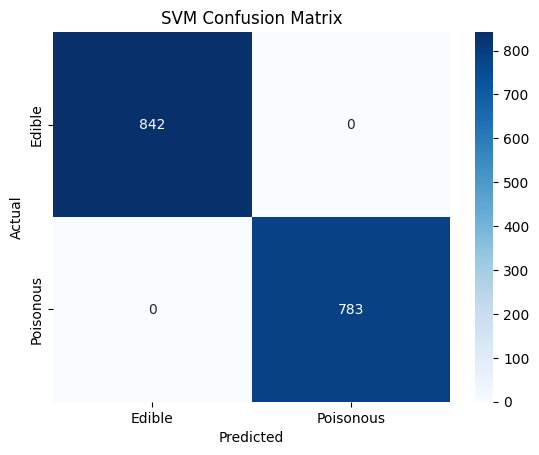

In [ ]:
# Display the confusion matrix

sns.heatmap(cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Edible', 'Poisonous'],
    yticklabels=['Edible', 'Poisonous']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")
plt.show()

In [ ]:
# Display precision, recall and F1-score

print(classification_report(
    y_test,
    y_pred,
    target_names=['Edible', 'Poisonous']
))

              precision    recall  f1-score   support

      Edible       1.00      1.00      1.00       842
   Poisonous       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



In [ ]:
# Define C and gamma values for tuning

parameter_grid = {
    'C': [0.1, 1, 10],
    'gamma': [0.1, 1, 10]
}

In [ ]:
# Find the best C and gamma values

grid_search = GridSearchCV(
    SVC(kernel='rbf'),
    parameter_grid,
    cv=5,
    scoring='accuracy'
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=SVC(),
             param_grid={'C': [0.1, 1, 10], 'gamma': [0.1, 1, 10]},
             scoring='accuracy')

In [ ]:
# Display the best parameters and accuracy

print("Best Parameters:", grid_search.best_params_)
print("Best Accuracy:", grid_search.best_score_)

Best Parameters: {'C': 1, 'gamma': 0.1}
Best Accuracy: 1.0


In [ ]:
# Train SVM using the best parameters

best_svm = SVC(
    kernel='rbf',
    C=grid_search.best_params_['C'],
    gamma=grid_search.best_params_['gamma']
)

best_svm.fit(X_train, y_train)

SVC(C=1, gamma=0.1)

In [ ]:
# Calculate final accuracy of optimized SVM

best_pred = best_svm.predict(X_test)

best_accuracy = accuracy_score(y_test, best_pred)

print("Final Accuracy:", best_accuracy)
print("Final Accuracy (%):", best_accuracy * 100)

Final Accuracy: 1.0
Final Accuracy (%): 100.0
